In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

In [3]:
class NoiseAug:
    def __init__(self, k=10):
        self.k = k
    
    def __call__(self, X, y):
        X_aug = [X]
        for i in range(self.k):
            noise = np.random.randn(*(X.shape))*0.01
            X_aug.append(X + noise)
        X_aug = np.concatenate(X_aug)
        y_aug = np.concatenate([y] * (self.k + 1))
        return X_aug, y_aug
    

In [4]:
class PrepareData:
    def __init__(
            self,
            transforms=[],
            augmentations=[]
            
        ):
        self.is_fit = False
        self.pipe_transforms = Pipeline(transforms)
        self.augmentations = augmentations
    
    def fit(self, X, y):
        self.pipe_transforms.fit(X)
        self.is_fit = True
    
    def transform(self, X, y, is_train=True):
        assert self.is_fit, 'not fitted'
        X = self.pipe_transforms.transform(X)
        
        if is_train:
            for aug in self.augmentations:
                X, y = aug(X, y)
        return X, y

In [5]:
df = pd.read_csv('complete_df.csv')
df.loc[df['avo850'].abs() > 1e3, 'avo850'] = np.nan
df.dropna(inplace=True)

X = df.drop(columns=['target', 'Th900_sst']).values
cols =  df.drop(columns=['target', 'Th900_sst']).columns
y = df['target'].values

In [6]:
pos = df[df['target'] == 1]
neg = df[df['target'] == 0]

n_pos_test = int(len(pos) * 0.2)
pos_train, pos_test = pos.iloc[:-n_pos_test], pos.iloc[-n_pos_test:]
neg_train, neg_test = train_test_split(neg, test_size=0.2, random_state=42)

train = pd.concat([pos_train, neg_train])
test = pd.concat([pos_test, neg_test])

X_train = train.drop(columns=['target', 'Th900_sst']).values
y_train = train['target'].values
X_test = test.drop(columns=['target', 'Th900_sst']).values
y_test = test['target'].values

In [7]:
augmentations = [NoiseAug(100)]
transforms = [('standard_scaler', StandardScaler())]
data_preparator = PrepareData(transforms, augmentations)
data_preparator.fit(X_train, y_train)

In [8]:
X_train_prep, y_train_prep = data_preparator.transform(X_train, y_train, is_train=True)
# X_valid_prep, y_valid_prep = data_preparator.transform(X_valid, y_valid, is_train=False)
X_test_prep, y_test_prep = data_preparator.transform(X_test, y_test, is_train=False)

Models

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier

In [10]:
regression = LogisticRegression(max_iter=1000)
regression.fit(X_train_prep, y_train_prep)

regression_score = regression.score(X_test_prep, y_test_prep)
regression_pred = regression.predict(X_test_prep)

In [11]:
svm = SVC()
svm.fit(X_train_prep, y_train_prep)

svm_score = svm.score(X_test_prep, y_test_prep)
svm_pred = svm.predict(X_test_prep)

In [12]:
rf = RandomForestClassifier()
rf.fit(X_train_prep, y_train_prep)

rf_score = rf.score(X_test_prep, y_test_prep)
rf_pred = rf.predict(X_test_prep)

In [13]:
cb = CatBoostClassifier()
cb.fit(X_train_prep, y_train_prep)

cb_score = cb.score(X_test_prep, y_test_prep)
cb_pred = cb.predict(X_test_prep)

Learning rate set to 0.071337
0:	learn: 0.5697500	total: 66.3ms	remaining: 1m 6s
1:	learn: 0.4397460	total: 74.4ms	remaining: 37.1s
2:	learn: 0.3558311	total: 85.3ms	remaining: 28.3s
3:	learn: 0.2896909	total: 96.3ms	remaining: 24s
4:	learn: 0.2465072	total: 105ms	remaining: 20.8s
5:	learn: 0.2104181	total: 113ms	remaining: 18.8s
6:	learn: 0.1802232	total: 122ms	remaining: 17.2s
7:	learn: 0.1498352	total: 130ms	remaining: 16.2s
8:	learn: 0.1328270	total: 140ms	remaining: 15.4s
9:	learn: 0.1062972	total: 148ms	remaining: 14.6s
10:	learn: 0.0954575	total: 157ms	remaining: 14.1s
11:	learn: 0.0805557	total: 165ms	remaining: 13.6s
12:	learn: 0.0739914	total: 174ms	remaining: 13.2s
13:	learn: 0.0636232	total: 182ms	remaining: 12.8s
14:	learn: 0.0580716	total: 190ms	remaining: 12.5s
15:	learn: 0.0539559	total: 199ms	remaining: 12.2s
16:	learn: 0.0495551	total: 208ms	remaining: 12.1s
17:	learn: 0.0456130	total: 221ms	remaining: 12.1s
18:	learn: 0.0418418	total: 230ms	remaining: 11.9s
19:	learn

In [14]:
print(f'Accuracy:\nLogistic regression:{round(regression_score,3)}, SVM:{round(svm_score,3)}, '\
      f'RandomForest:{round(rf_score,3)}, CatBoost:{round(cb_score,3)}')

Accuracy:
Logistic regression:0.952, SVM:0.948, RandomForest:0.965, CatBoost:0.956


In [15]:
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

In [16]:
predicted = [regression_pred, svm_pred, rf_pred, cb_pred]

recall = []
precision = []
f1 = []

for i in predicted:
    recall.append(recall_score(y_test_prep, i))
    precision.append(precision_score(y_test_prep, i))
    f1.append(f1_score(y_test_prep, i))

In [17]:
print(f'Precision:\nLogistic regression:{round(precision[0],3)},'\
      f' SVM:{round(precision[1],3)}, '\
      f'RandomForest:{round(precision[2],3)},' \
      f' CatBoost:{round(precision[3],3)}')

Precision:
Logistic regression:0.955, SVM:0.981, RandomForest:0.973, CatBoost:0.981


In [18]:
print(f'Recall:\nLogistic regression:{round(recall[0],3)},'\
      f' SVM:{round(recall[1],3)}, '\
      f'RandomForest:{round(recall[2],3)},' \
      f' CatBoost:{round(recall[3],3)}')

Recall:
Logistic regression:0.947, SVM:0.912, RandomForest:0.956, CatBoost:0.929


In [19]:
print(f'F1:\nLogistic regression:{round(f1[0],3)},'\
      f' SVM:{round(f1[1],3)}, '\
      f'RandomForest:{round(f1[2],3)},' \
      f' CatBoost:{round(f1[3],3)}')

F1:
Logistic regression:0.951, SVM:0.945, RandomForest:0.964, CatBoost:0.955


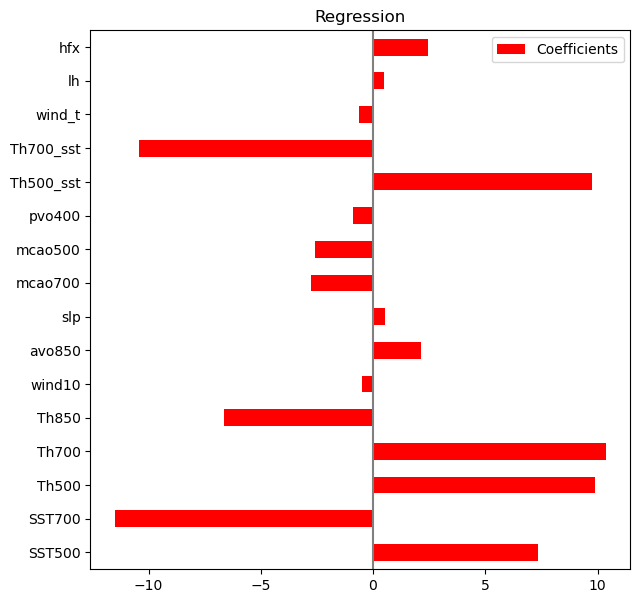

In [20]:
coefs = pd.DataFrame(
    regression.coef_.reshape(16,1), index=cols, columns=["Coefficients"]
)

coefs.plot(kind="barh", figsize=(9, 7), color = 'red')
plt.title("Regression")
plt.axvline(x=0, color=".5")
plt.subplots_adjust(left=0.3)

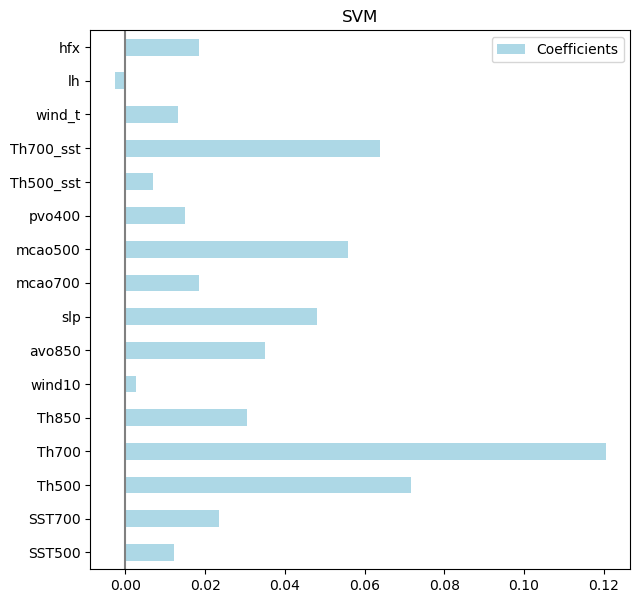

In [21]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(svm, X_test_prep, y_test_prep)

coefs = pd.DataFrame(
    perm_importance.importances_mean.reshape(16,1), index=cols, columns=["Coefficients"]
)

coefs.plot(kind="barh", figsize=(9, 7), color = 'lightblue')
plt.title("SVM")
plt.axvline(x=0, color=".5")
plt.subplots_adjust(left=0.3)

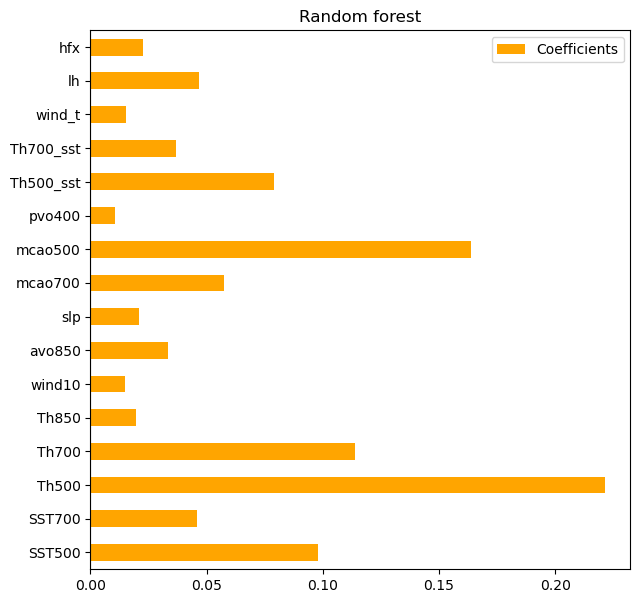

In [23]:
coefs = pd.DataFrame(
    rf.feature_importances_.reshape(16,1), index=cols, columns=["Coefficients"]
)

coefs.plot(kind="barh", figsize=(9, 7), color = 'orange')
plt.title("Random forest")
plt.axvline(x=0, color=".5")
plt.subplots_adjust(left=0.3)

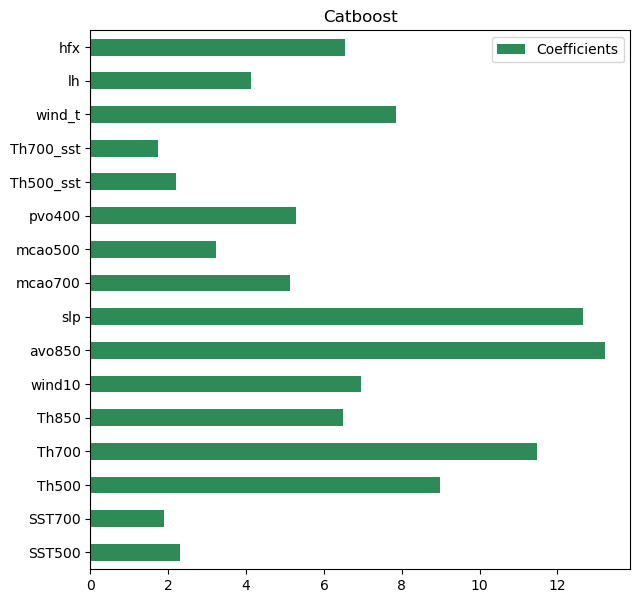

In [24]:
coefs = pd.DataFrame(
    cb.feature_importances_.reshape(16,1), index=cols, columns=["Coefficients"]
)

coefs.plot(kind="barh", figsize=(9, 7), color = 'seagreen')
plt.title("Catboost")
plt.axvline(x=0, color=".5")
plt.subplots_adjust(left=0.3)